# ARTE4110U Challenge 4: Design a Deep Network for MNIST

**Individual challenge · Dr. Hani Sami**

Build a handwritten-digit classifier using a real image dataset. You will choose
the number of hidden layers and their widths, implement your architectures in
PyTorch, and compare their accuracy. This applies Lecture 04: composition,
depth and width, matrix shapes, and parameter counts.

**Your work:** prepare and inspect image tensors, build two deep fully connected
networks, explain your design choices, and interpret the results.
**Provided:** data download and split, training loop, cross-entropy loss,
Adam optimizer, model selection support, and complete accuracy code. You do
not need to derive the loss, explain Adam, or implement backpropagation.

Complete the **TODO** code and write short answers beside your work. Submit
one completed Jupyter notebook on Canvas; no separate report is required.
Follow the course policy on AI tools. Run cells in order.

## 1. Load a real image dataset

MNIST contains grayscale images of handwritten digits **0–9**. Each image
is 28 × 28 pixels. We will split the official 60,000 training images into
50,000 training and 10,000 validation images. The official 10,000 test images
are reserved for the final evaluation.

### Where to get the dataset

**Dataset source:** [MNIST handwritten-digit dataset — original dataset page](https://yann.lecun.org/exdb/mnist/index.html).

**How to get it for this challenge:** Complete the image-transform TODO and
run the supplied `datasets.MNIST(..., download=True)` cell below. PyTorch
will download the training images, training labels, test images, and test
labels automatically into `./mnist_data/`. You do not need to download,
unzip, or upload the files manually.

**PyTorch loading instructions:** [torchvision MNIST dataset documentation](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html).
The code uses `train=True` for the original training set and `train=False`
for the official test set. Validation images are split from the training set.

Use Google Colab or a local Jupyter environment. The first download requires
internet access. If imports fail because a library is missing, install PyTorch,
torchvision, NumPy, and Matplotlib, then restart the kernel if needed. Installation
instructions: [PyTorch](https://pytorch.org/get-started/locally/).

In [3]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
EPOCHS = 5
LEARNING_RATE = 0.001
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


### Prepare the image values

The downloaded images begin as image objects with integer pixel values
from 0 to 255. `transforms.ToTensor()` converts each image to a
`torch.float32` tensor with shape `(1, 28, 28)` and scales its pixel values
to `[0, 1]`. The `1` is the grayscale channel count.

**TODO:** Set `image_transform` to `transforms.ToTensor()`, then run the
supplied download and split code. Keep the split and training settings fixed
when comparing architectures. No additional standardization is required here.

In [4]:
image_transform = transforms.ToTensor()  # TODO: replace None with the image-to-tensor transform.
assert image_transform is not None, 'Complete the image_transform TODO first.'

full_train_dataset = datasets.MNIST(
    root='./mnist_data', train=True, download=True, transform=image_transform
)
test_dataset = datasets.MNIST(
    root='./mnist_data', train=False, download=True, transform=image_transform
)
train_dataset, val_dataset = random_split(
    full_train_dataset, [50000, 10000],
    generator=torch.Generator().manual_seed(SEED)
)
print('Training images:', len(train_dataset))
print('Validation images:', len(val_dataset))
print('Test images:', len(test_dataset))

def make_loaders():
    # Recreate this seeded generator for every architecture: same batch order.
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
        generator=torch.Generator().manual_seed(SEED)
    )
    train_eval_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )
    return train_loader, train_eval_loader, val_loader

train_loader, train_eval_loader, val_loader = make_loaders()
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

Training images: 50000
Validation images: 10000
Test images: 10000


## 2. Inspect the inputs and labels

**TODO:** Print the shape, data type, minimum, and maximum of one image.
Print its label. Display 12 training images with their labels.

**Hint:** `train_dataset[i]` returns `(image, label)`.
Use `image.squeeze()` to remove the grayscale channel dimension when
displaying it with `imshow(..., cmap='gray')`.

Shape: torch.Size([1, 28, 28])
Data type: torch.float32
Minimum: 0.0
Maximum: 1.0
Label: 6


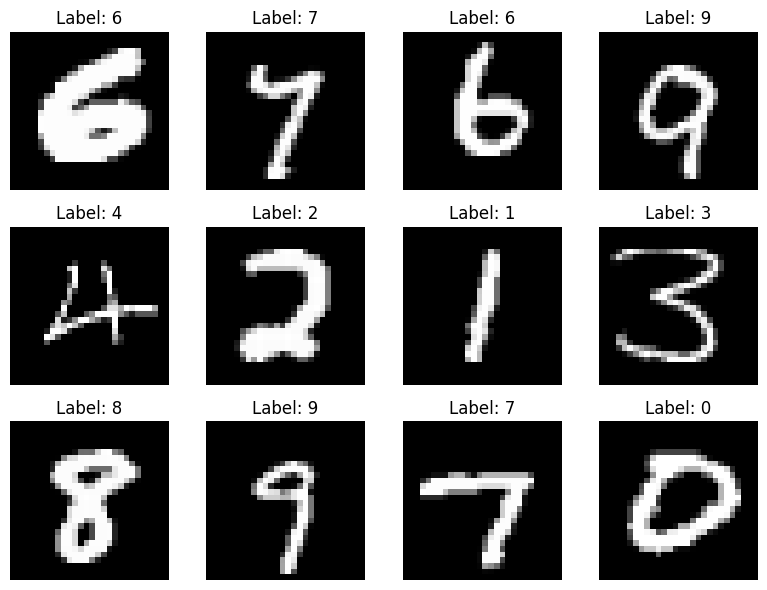

Image batch: torch.Size([128, 1, 28, 28]) torch.float32
Label batch: torch.Size([128]) torch.int64
Flattened batch: torch.Size([128, 784])


In [9]:
# TODO: inspect one image and its label.
# TODO: display 12 training images in a labeled grid.
image, label = train_dataset[0]

print('Shape:', image.shape)
print('Data type:', image.dtype)
print('Minimum:', image.min().item())
print('Maximum:', image.max().item())
print('Label:', label)

fig, axes = plt.subplots(3, 4, figsize=(8, 6))
for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap='gray')
    ax.set_title(f'Label: {label}')
    ax.axis('off')

plt.tight_layout()
plt.show()


### From images to the input of a fully connected network

A batch of images has shape `(B, 1, 28, 28)`. A fully connected model needs
one vector per image: `(B, input_dim)`. Use `nn.Flatten(start_dim=1)` to
combine the channel, height, and width dimensions while preserving the batch.

**TODO:** Complete the code below. Determine `input_dim` from the image
dimensions and `output_dim` from the number of digit classes.

In [10]:
images, labels = next(iter(train_loader))
print('Image batch:', images.shape, images.dtype)
print('Label batch:', labels.shape, labels.dtype)

input_dim = images[0].numel()
output_dim = 10

flatten = nn.Flatten(start_dim=1)
flat_images = flatten(images)
print('Flattened batch:', flat_images.shape)

Image batch: torch.Size([128, 1, 28, 28]) torch.float32
Label batch: torch.Size([128]) torch.int64
Flattened batch: torch.Size([128, 784])


**Your explanation:** Why must you preserve the batch dimension when
flattening? Why does each image need one integer label rather than a label
for every pixel? State the image-batch, flattened-batch, and label shapes.

_Write your answer here._
We preserve the batch dimensions so each image is a separate example. The image has shape (128, 1, 28, 28) and the flattened: (128, 784), label: (128,). Each image has one label because the label identifies the digit shown in the full image rather than classifying a single pixel.

## 3. Choose two deep architectures

There is no single required number of hidden layers. Choose **Model A**
and **Model B**, each with at least **two hidden layers**. For this challenge,
keep each model to at most **five hidden layers**, with **16–256 units per
hidden layer**, so training stays manageable.

Choose a useful comparison: change the number of hidden layers **or**
the widths, and explain what you want to learn from that change. For a
depth comparison, keep a common width in the shared layers and add/remove
a layer. For a width comparison, keep the number of layers fixed.
You may use different widths within a network.

Use only `nn.Flatten`, `nn.Linear`, and `nn.ReLU`. Every hidden linear
layer is followed by ReLU; the final linear layer returns one raw score
(a **logit**) per digit class. **Do not put ReLU, sigmoid, or softmax after
the output layer.** The supplied cross-entropy loss expects raw scores.

Depth and widths are choices you make before training. Weights and biases
are the parameters training learns. These architectures do not need the
same parameter count, but you must report their counts: any performance
difference may reflect both architecture and parameter budget.

In [11]:
# TODO: replace None with your tuple of hidden-layer widths for each model.
# A tuple such as (width_1, width_2, ...) describes one network.
architectures = {
    'Model A': (64, 64),
    'Model B': (64, 64, 64),
}

for name, widths in architectures.items():
    assert isinstance(widths, tuple), f'{name}: enter a tuple of hidden widths.'
    assert 2 <= len(widths) <= 5, 'Use two to five hidden layers.'
    assert all(isinstance(w, int) and 16 <= w <= 256 for w in widths)
assert architectures['Model A'] != architectures['Model B'], 'Choose different architectures.'

**Your plan:** Before training, write each architecture as
`input → hidden widths → output`. State its depth and widths, and give
one reason for each design. What does Model B change relative to Model A?

_Write your answer here._

Model A has two hidden layers: 784 -> 64 -> 64 -> 10. Model B has three: 784 -> 64 -> 64 -> 64 -> 10. I’m comparing depth to see whether adding a hidden layer improves validation accuracy, model B also will have more trainable parameters.

## 4. Implement a configurable PyTorch model

Complete the `DigitClassifier` class below so the same class can build
either architecture from its tuple of widths.

**Hints:** Start with the flattened input width. For each hidden width, add
`nn.Linear(previous_width, current_width)` and `nn.ReLU()` to a list, then
update `previous_width`. After the loop, add the final linear output layer.
Wrap the list with `nn.Sequential(*layers)`.

In `forward`, flatten the incoming images and pass them through your network.
This implements the lecture's composition: each layer's output becomes
the next layer's input.

In [13]:
class DigitClassifier(nn.Module):
    def __init__(self, input_dim, hidden_widths, output_dim):
        super().__init__()
        # TODO: create self.flatten using nn.Flatten.
        # TODO: create self.network using nn.Linear, nn.ReLU, and nn.Sequential.
        #       Use hidden_widths to support either chosen architecture.
        self.flatten = nn.Flatten(start_dim=1)
        layers = []
        previous_width = input_dim

        for current_width in hidden_widths:
          layers.append(nn.Linear(previous_width, current_width))
          layers.append(nn.ReLU())
          previous_width = current_width

        layers.append(nn.Linear(previous_width, output_dim))
        self.network = nn.Sequential(*layers)

    def forward(self, images):
        # TODO: flatten the images and return the network output.
        values = self.flatten(images)
        return self.network(values)

### Check the shapes and count parameters before training

For `nn.Linear(a, b)`, the weight matrix has shape `(b, a)`, its bias has
shape `(b,)`, and the trainable parameter count is `a*b + b`.
ReLU and Flatten have no trainable parameters.

**TODO:** Print both models and their trainable parameter totals using
`sum(p.numel() for p in model.parameters())`. Run the supplied shape trace.
It shows how a batch moves through your actual model.

In [14]:
preview_models = {
    name: DigitClassifier(input_dim, widths, output_dim)
    for name, widths in architectures.items()
}

# TODO: print each model and its trainable parameter total.
for name, model in preview_models.items():
    print(f'\n{name}:')
    print(model)
    parameter_count = sum(p.numel() for p in model.parameters())
    print('Trainable parameters:', parameter_count)

    print(f'{name}: shape trace')
    model.eval()
    with torch.no_grad():
        values = model.flatten(images)
        print('Flatten:', tuple(values.shape))
        for layer in model.network:
            values = layer(values)
            print(type(layer).__name__, '->', tuple(values.shape))
        logits = model(images)

    assert logits.shape == (images.shape[0], output_dim)
    assert torch.isfinite(logits).all()


Model A:
DigitClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)
Trainable parameters: 55050
Model A: shape trace
Flatten: (128, 784)
Linear -> (128, 64)
ReLU -> (128, 64)
Linear -> (128, 64)
ReLU -> (128, 64)
Linear -> (128, 10)

Model B:
DigitClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=10, bias=True)
  )
)
Trainable parameters: 59210
Model B: shape trace
Flatten: (128, 784)
Linear -> (128, 64)
ReLU -> (128, 64)
Linear -> (128, 64

**Your calculation:** For Model A, make a table with one row per linear
layer: input width, output width, weight-matrix shape, bias-vector shape,
and parameter count. Sum the counts and check against PyTorch.
Include the output layer. Explain why Model B has more, fewer, or the same
number of parameters.

_Write your table and explanation here._

| Linear layer | Input → output | Weight shape | Bias shape | Parameters |
|---|---:|---:|---:|---:|
| 1 | 784 → 64 | `(64, 784)` | `(64,)` | `784 × 64 + 64 = 50,240` |
| 2 | 64 → 64 | `(64, 64)` | `(64,)` | `64 × 64 + 64 = 4,160` |
| 3 (output) | 64 → 10 | `(10, 64)` | `(10,)` | `64 × 10 + 10 = 650` |
| **Total** |  |  |  | **55,050** |

Model b has 4160 more parameters because it includes an additional layer. Flatten and ReLU have no trainable parameters.

## 5. Train using the supplied code

The code below handles training. Keep **5 epochs**, batch size **128**,
learning rate **0.001**, and seed **42** for both models.

- `nn.CrossEntropyLoss()` measures classification error for the training updates.
- Adam updates the weights using gradients computed by PyTorch.
- Labels remain class indices `0–9`, with tensor shape `(B,)` and data type
  `torch.long`; do not one-hot encode or reshape them to `(B, 1)`.
- Model outputs have shape `(B, output_dim)` and remain raw scores.

You only need to use this training support at this stage. The loss function,
optimizer details, and gradient calculations will be covered later.

### Accuracy calculation — complete code provided

For each image, select the digit with the largest output score using
`argmax(dim=1)`. Accuracy is **100 × correct predictions / number of images**.
The function below counts examples across all batches; it does not take
an unweighted average of batch percentages.

In [15]:
def evaluate_accuracy(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_images, batch_labels in loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)
            logits = model(batch_images)
            predicted_digits = logits.argmax(dim=1)
            correct += (predicted_digits == batch_labels).sum().item()
            total += batch_labels.size(0)
    return 100.0 * correct / total


def run_experiment(hidden_widths):
    torch.manual_seed(SEED)
    train_loader, train_eval_loader, val_loader = make_loaders()
    model = DigitClassifier(input_dim, hidden_widths, output_dim).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {'train_accuracy': [], 'val_accuracy': []}
    best_val_accuracy = -1.0
    best_state = None
    best_epoch = None

    for epoch in range(1, EPOCHS + 1):
        model.train()
        for batch_images, batch_labels in train_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)
            optimizer.zero_grad()
            logits = model(batch_images)
            loss = loss_fn(logits, batch_labels)
            loss.backward()
            optimizer.step()

        # Measure both accuracies using the weights after this epoch.
        train_accuracy = evaluate_accuracy(model, train_eval_loader)
        val_accuracy = evaluate_accuracy(model, val_loader)
        history['train_accuracy'].append(train_accuracy)
        history['val_accuracy'].append(val_accuracy)
        print(f'Epoch {epoch}/{EPOCHS}: train {train_accuracy:.2f}% | val {val_accuracy:.2f}%')

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

    # Restore this architecture's best validation checkpoint.
    model.load_state_dict(best_state)
    return {
        'model': model,
        'widths': hidden_widths,
        'depth': len(hidden_widths),
        'parameters': sum(p.numel() for p in model.parameters()),
        'best_epoch': best_epoch,
        'val_accuracy': best_val_accuracy,
        'train_accuracy': evaluate_accuracy(model, train_eval_loader),
        'history': history,
    }


results = {}
for name, widths in architectures.items():
    print(f'\nTraining {name}: {widths}')
    results[name] = run_experiment(widths)


Training Model A: (64, 64)
Epoch 1/5: train 92.58% | val 92.01%
Epoch 2/5: train 94.65% | val 93.87%
Epoch 3/5: train 95.79% | val 94.64%
Epoch 4/5: train 96.69% | val 95.39%
Epoch 5/5: train 97.39% | val 96.09%

Training Model B: (64, 64, 64)
Epoch 1/5: train 92.62% | val 92.07%
Epoch 2/5: train 94.85% | val 94.05%
Epoch 3/5: train 96.12% | val 95.10%
Epoch 4/5: train 97.07% | val 95.89%
Epoch 5/5: train 97.60% | val 96.11%


## 6. Compare designs and select a model

**TODO:** Display a comparison table with: model name, hidden widths,
depth, parameter count, selected epoch, training accuracy, and validation
accuracy. The returned results refer to each model's **best validation
checkpoint**, not necessarily its final epoch.

Plot the supplied training and validation accuracy histories with labeled
axes and legends. Select the architecture with the higher validation accuracy.
For a tie, select the smaller model. Do not use test accuracy to choose a model.

Model      Hidden widths      Depth   Parameters  Best epoch  Train acc.   Val acc.
Model A    (64, 64)               2       55,050           5      97.39%     96.09%
Model B    (64, 64, 64)           3       59,210           5      97.60%     96.11%


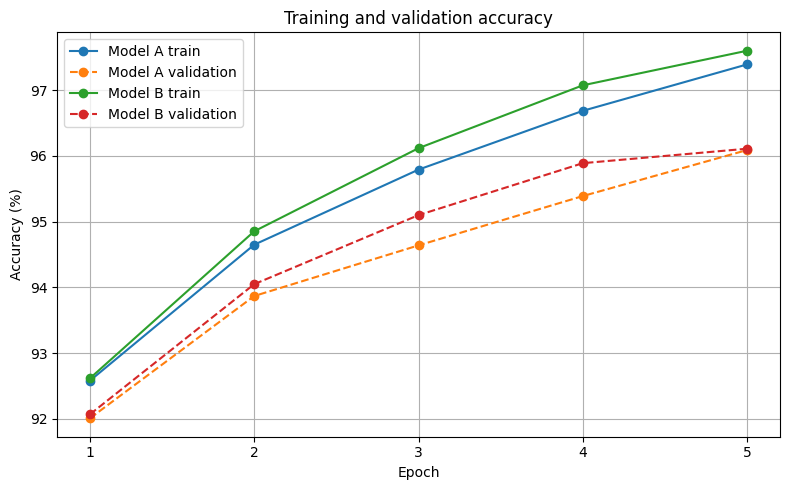

Selected: Model B | hidden widths: (64, 64, 64) | best epoch: 5


In [16]:
# TODO: display the two-row comparison table using results.
print(
    f"{'Model':<10} {'Hidden widths':<18} {'Depth':>5} "
    f"{'Parameters':>12} {'Best epoch':>11} "
    f"{'Train acc.':>11} {'Val acc.':>10}"
)

for name, result in results.items():
    print(
        f"{name:<10} {str(result['widths']):<18} {result['depth']:>5} "
        f"{result['parameters']:>12,} {result['best_epoch']:>11} "
        f"{result['train_accuracy']:>10.2f}% "
        f"{result['val_accuracy']:>9.2f}%"
    )

plt.figure(figsize=(8, 5))

for name, result in results.items():
    epochs = range(1, len(result['history']['train_accuracy']) + 1)
    plt.plot(
        epochs, result['history']['train_accuracy'],
        marker='o', label=f'{name} train'
    )
    plt.plot(
        epochs, result['history']['val_accuracy'],
        marker='o', linestyle='--', label=f'{name} validation'
    )
# TODO: plot training and validation accuracy against epoch for both models.
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Training and validation accuracy')
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

selected_name = max( # TODO: choose using validation accuracy (smaller model for a tie).
    results,
    key=lambda name: (
        results[name]['val_accuracy'],
        -results[name]['parameters']
    )
)
selected_result = results[selected_name]
selected_model = selected_result['model']

print(
    'Selected:', selected_name,
    '| hidden widths:', selected_result['widths'],
    '| best epoch:', selected_result['best_epoch']
)

## 7. Report test accuracy and inspect predictions

Once you have selected the architecture and checkpoint, run the supplied
test-accuracy code **once**. The test images have not been used for training
or model selection. Report the percentage; do not change your architecture
based on the test score.

The second supplied cell displays six correct predictions and up to six
incorrect predictions, when available. It helps you inspect what the selected
model learned. Green titles indicate correct predictions and red titles
indicate errors. A confident-looking or visually clear digit can still be
misclassified.

In [17]:
test_accuracy = evaluate_accuracy(selected_model, test_loader)
print(f'{selected_name}: test accuracy = {test_accuracy:.2f}%')

Model B: test accuracy = 96.64%


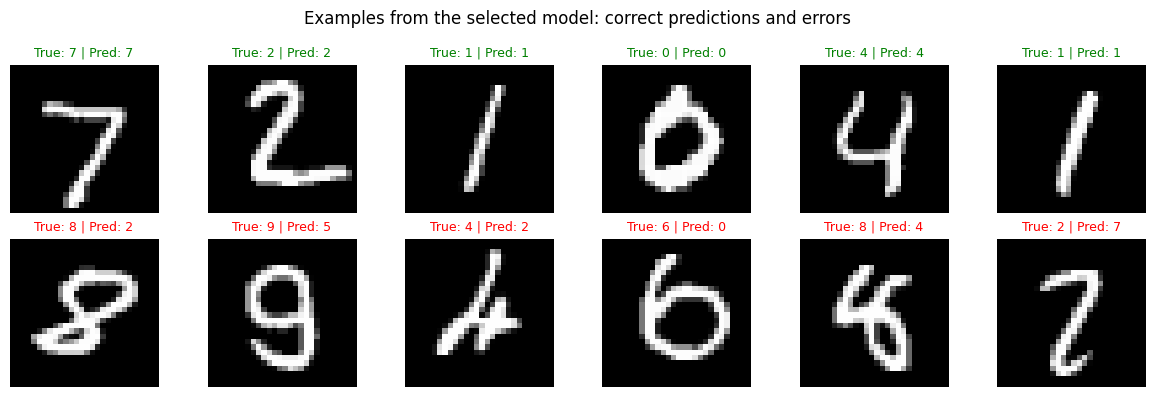

In [18]:
correct_examples, incorrect_examples = [], []
selected_model.eval()
with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        predicted_digits = selected_model(batch_images.to(device)).argmax(dim=1).cpu()
        for image, label, prediction in zip(batch_images, batch_labels, predicted_digits):
            example = (image, int(label), int(prediction))
            bucket = correct_examples if int(label) == int(prediction) else incorrect_examples
            if len(bucket) < 6:
                bucket.append(example)
        if len(correct_examples) == 6 and len(incorrect_examples) == 6:
            break

examples = correct_examples + incorrect_examples
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for ax in axes.ravel():
    ax.axis('off')
for ax, (image, label, prediction) in zip(axes.ravel(), examples):
    ax.imshow(image.squeeze().numpy(), cmap='gray')
    ax.set_title(f'True: {label} | Pred: {prediction}',
                 color='green' if label == prediction else 'red', fontsize=9)
fig.suptitle('Examples from the selected model: correct predictions and errors')
plt.tight_layout()
plt.show()

## 8. Explain your architecture and results

Answer briefly, using your own table and plots:

1. What depth and widths did you choose? Which model did you select, and why?
   Cite its validation accuracy and parameter count, then report its test accuracy.
2. Did changing depth or width improve validation accuracy? Does this experiment
   establish that adding hidden layers always improves a model? Explain.
3. How does the model compose transformations of the 784 pixel values?
   Explain how one hidden layer's output becomes the next layer's input.
4. Compare training and validation accuracy. Is there a noticeable gap?
   Describe one incorrect prediction and a possible visual reason for the error.
5. If the input images were 32 × 32 grayscale instead, what input width would
   you need? Would the output width change if the task still used digits 0–9?

_Write your answers here._

1. | Model | Architecture | Hidden layers | Parameters | Validation accuracy |
|---|---|---:|---:|---:|
| A | `784 → 64 → 64 → 10` | 2 | 55,050 | 96.09% |
| B | `784 → 64 → 64 → 64 → 10` | 3 | 59,210 | 96.11% |

I selected model B because it had higher validation accuracy, it test accuracy was 96.64%

2. Model B validation accuracy was 0.02% higher than model A, this is very small improvement, and model B had more parameters. This experiment does not show that adding hidden layers always improves a model, it compares only these two architectures under these training settings.

3. The model flattens each image to 784 pixels, in model B those values pass through linear layers of width 64, 64, and 64, with ReLU after each hidden layer, each layer output becomes the next layer input. The final layer transforms the last 64 values into 10 scores one for each digit.

4. Model B training accuracy was 97.60%, compared with 96.11% validation accuracy, a gap of 1.49% points. Both accuracies increased over the five epochs, and the gap is modest. One error was a true 6 predicted as 0, its rounded loop may have made it look like a zero.

5. A 32x32 grayscale image has 1024 pixels so the input width would be 1024, the ioutput would stay 10 because the task still classifies digits 0-9.

## Completion checklist

- [x] Converted and inspected the MNIST image tensors and displayed examples.
- [x] Explained batch shapes, flattening, input width, and output width.
- [x] Designed and implemented two different deep architectures.
- [x] Traced layer shapes and checked a manual parameter count against PyTorch.
- [x] Trained both models using the same supplied settings.
- [x] Reported a comparison table and plotted accuracy histories.
- [x] Selected using validation accuracy, then reported test accuracy.
- [x] Inspected predictions and answered the interpretation questions.

**Success means a working, explained architecture and an honest comparison.**
A deeper model does not have to win, and there is no required accuracy threshold.

### Optional references

- [PyTorch neural-network modules](https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html)
- [MNIST in torchvision](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html)
- [Image-to-tensor conversion](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.ToTensor.html)
- [CrossEntropyLoss input requirements](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)

The first reference uses FashionMNIST; use it for the PyTorch model structure,
and use the MNIST digit dataset supplied in this notebook.